In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [22]:
relative_data_path = Path('data/raw/ecommerce_demand_weekly.csv')
search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
data_path = next(
    (root / relative_data_path for root in search_roots if (root / relative_data_path).is_file()),
    None,
)
if data_path is None:
    data_path = next(
        (
            candidate
            for root in search_roots
            for candidate in root.glob('*/data/raw/ecommerce_demand_weekly.csv')
            if candidate.is_file()
        ),
        None,
    )
if data_path is None:
    raise FileNotFoundError(f'Could not locate {relative_data_path} from {Path.cwd()}')

project_root = data_path.parents[2]
df1 = pd.read_csv(data_path)
sorted_df1 = df1.sort_values(by='date', ascending=False)
sorted_df1.head(20)

,date,sku,category,region,units_sold,true_demand,price,on_promo,stockout,returns,seasonal_index,is_new_launch,is_declining,month,net_units,revenue
8029,2024-12-30,BOO-1027,books_media,North,6,6,20.0,0,0,0,1.0,0,0,12,6,120.0
20831,2024-12-30,SPO-1035,sports_outdoor,West,48,48,70.0,0,0,10,1.0,0,0,12,38,2660.0
17420,2024-12-30,HOM-1030,home_kitchen,South,27,27,60.0,0,0,3,1.0,0,0,12,24,1440.0
11253,2024-12-30,ELE-1029,electronics,North,72,72,180.0,0,0,6,1.0,0,0,12,66,11880.0
21150,2024-12-30,SPO-1039,sports_outdoor,Central,29,29,70.0,0,0,4,1.0,0,0,12,25,1750.0
525,2024-12-30,APP-1006,apparel,West,46,46,45.0,0,0,9,1.0,0,0,12,37,1665.0
21920,2024-12-30,TOY-1010,toys_games,Central,36,36,35.0,0,0,3,1.0,0,0,12,33,1155.0
1875,2024-12-30,APP-1023,apparel,West,42,42,45.0,0,0,10,1.0,0,0,12,32,1440.0
6514,2024-12-30,BOO-1006,books_media,South,33,33,15.0,1,0,2,1.0,0,0,12,31,465.0
16295,2024-12-30,HOM-1017,home_kitchen,West,51,51,60.0,0,0,2,1.0,0,0,12,49,2940.0


In [23]:
dictionary_path = next(
    (
        candidate
        for candidate in (
            project_root / 'data_dictionary_ecom_demand.csv',
            project_root.parent / 'data_dictionary_ecom_demand.csv',
        )
        if candidate.is_file()
    ),
    None,
)
if dictionary_path is None:
    raise FileNotFoundError('Could not locate data_dictionary_ecom_demand.csv near the project root')
df2 = pd.read_csv(dictionary_path)
df2.head(20)

,column,type,description
0,date,date,Week (Monday)
1,sku,string,Product SKU code
2,category,string,electronics / apparel / home_kitchen / beauty ...
3,region,string,North / South / East / West / Central
4,units_sold,int,OBSERVED units sold (capped/zeroed during stoc...
5,true_demand,int,GROUND TRUTH latent demand (equals units_sold ...
6,price,float,Unit price this week (reflects ~25% promo disc...
7,on_promo,int,1 if the SKU was on promotion this week (flag ...
8,stockout,int,1 if a supply interruption capped sales below ...
9,returns,int,Units returned (category-dependent return rate)


In [24]:
sorted_df1.info()
sorted_df1.shape

<class 'pandas.DataFrame'>
Index: 24310 entries, 8029 to 9699
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            24310 non-null  str    
 1   sku             24310 non-null  str    
 2   category        24310 non-null  str    
 3   region          24310 non-null  str    
 4   units_sold      24310 non-null  int64  
 5   true_demand     24310 non-null  int64  
 6   price           24310 non-null  float64
 7   on_promo        24310 non-null  int64  
 8   stockout        24310 non-null  int64  
 9   returns         24310 non-null  int64  
 10  seasonal_index  24310 non-null  float64
 11  is_new_launch   24310 non-null  int64  
 12  is_declining    24310 non-null  int64  
 13  month           24310 non-null  int64  
 14  net_units       24310 non-null  int64  
 15  revenue         24310 non-null  float64
dtypes: float64(3), int64(9), str(4)
memory usage: 3.2 MB


(24310, 16)

In [25]:
sorted_df1.describe()

,units_sold,true_demand,price,on_promo,stockout,returns,seasonal_index,is_new_launch,is_declining,month,net_units,revenue
count,24310.000000,24310.000000,24310.000000,24310.000000,24310.000000,24310.000000,24310.000000,24310.000000,24310.000000,24310.000000,24310.000000,24310.000000
mean,42.954545,44.612341,53.833299,0.113369,0.043439,4.428219,1.071850,0.105306,0.073756,6.804689,38.526327,1815.128959
std,32.924830,32.621677,48.284592,0.317050,0.203847,6.620444,0.262574,0.306954,0.261378,3.459733,29.859423,2085.220567
min,0.000000,0.000000,11.250000,0.000000,0.000000,0.000000,0.712000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,20.000000,22.000000,20.000000,0.000000,0.000000,1.000000,0.939000,0.000000,0.000000,4.000000,18.000000,630.000000
50%,34.000000,35.000000,35.000000,0.000000,0.000000,2.000000,0.999000,0.000000,0.000000,7.000000,30.000000,1190.000000
75%,58.000000,59.000000,60.000000,0.000000,0.000000,5.000000,1.062000,0.000000,0.000000,10.000000,51.000000,2160.000000
max,279.000000,279.000000,180.000000,1.000000,1.000000,76.000000,2.354000,1.000000,1.000000,12.000000,252.000000,22815.000000


In [26]:
# Exact binary indicator flag columns present in df1
binary_cols = ['on_promo', 'stockout', 'is_new_launch', 'is_declining']

# Convert from int64 to uint8 (or bool)
sorted_df1[binary_cols] = sorted_df1[binary_cols].astype('bool')
sorted_df1.head()

,date,sku,category,region,units_sold,true_demand,price,on_promo,stockout,returns,seasonal_index,is_new_launch,is_declining,month,net_units,revenue
8029,2024-12-30,BOO-1027,books_media,North,6,6,20.0,False,False,0,1.0,False,False,12,6,120.0
20831,2024-12-30,SPO-1035,sports_outdoor,West,48,48,70.0,False,False,10,1.0,False,False,12,38,2660.0
17420,2024-12-30,HOM-1030,home_kitchen,South,27,27,60.0,False,False,3,1.0,False,False,12,24,1440.0
11253,2024-12-30,ELE-1029,electronics,North,72,72,180.0,False,False,6,1.0,False,False,12,66,11880.0
21150,2024-12-30,SPO-1039,sports_outdoor,Central,29,29,70.0,False,False,4,1.0,False,False,12,25,1750.0


In [27]:
sorted_df1[sorted_df1['stockout'] == True].head(10)

,date,sku,category,region,units_sold,true_demand,price,on_promo,stockout,returns,seasonal_index,is_new_launch,is_declining,month,net_units,revenue
993,2024-12-30,APP-1012,apparel,North,28,122,45.0,False,True,5,1.000,False,False,12,23,1035.0
5339,2024-12-30,BEA-1030,beauty,West,5,45,25.0,False,True,0,1.000,False,False,12,5,125.0
114,2024-12-30,APP-1000,apparel,West,6,48,45.0,False,True,3,1.000,False,False,12,3,135.0
4693,2024-12-30,BEA-1020,beauty,South,0,53,25.0,False,True,0,1.000,False,False,12,0,0.0
20709,2024-12-30,SPO-1034,sports_outdoor,North,3,23,70.0,False,True,1,1.000,False,False,12,2,140.0
17780,2024-12-30,HOM-1035,home_kitchen,South,3,23,60.0,False,True,0,1.000,False,False,12,3,180.0
11871,2024-12-30,ELE-1038,electronics,South,11,45,180.0,False,True,3,1.000,False,False,12,8,1440.0
9275,2024-12-30,ELE-1002,electronics,South,8,50,180.0,False,True,2,1.000,False,False,12,6,1080.0
2899,2024-12-23,APP-1037,apparel,Central,19,71,45.0,False,True,9,1.571,False,False,12,10,450.0
12148,2024-12-23,GRO-1002,grocery,North,10,119,15.0,False,True,1,1.176,False,False,12,9,135.0


In [28]:
# Check for duplicate indices/rows
print("Duplicate rows:", sorted_df1.duplicated().sum())

Duplicate rows: 0


In [29]:
# Validate business logic
sales_gt_demand = (sorted_df1['units_sold'] > sorted_df1['true_demand']).sum()
print(f"Rows where units_sold > true_demand: {sales_gt_demand}")

Rows where units_sold > true_demand: 0


In [30]:
# Verify revenue calculation consistency (price * net_units = revenue)
expected_revenue = sorted_df1['net_units'] * sorted_df1['price']
revenue_diff = abs((sorted_df1['revenue'] - expected_revenue)).max()
print(f"Max difference between calculated and reported revenue: {revenue_diff}")

Max difference between calculated and reported revenue: 0.0


The business logic checks implemented in the data quality steps were chosen based on the underlying domain rules defined in the data dictionary (df2) and real-world supply chain dynamics:
1. Observed Sales vs. Latent Demand (units_sold <= true_demand):
    Basis: Physical supply limits dictate that a company cannot fulfill more orders than actual market demand. When stockouts occur (stockout == 1), sales are capped below full demand, meaning actual sales must always be less than or equal to latent customer demand.
2. Revenue Formulation (revenue == net_units * price):
    Basis: Financial accounting logic defines gross revenue as sold units multiplied by realized unit price, minus customer returns (net_units = units_sold - returns). The dataset confirms that revenue directly equals net_units * price down to the exact decimal.
3. Promotional Discount Dynamics (on_promo impact on price):
    Basis: Promotional campaigns are designed to stimulate sales by lowering prices. As specified in the dictionary, promotional weeks (on_promo == 1) reflect an average ~25% price reduction compared to standard non-promotional weeks (on_promo == 0).
4. Stockout Signal Validation (stockout == 1):
    Basis: Supply chain management requires tracking inventory constraints. When a stockout occurs, units_sold drops significantly below true_demand (e.g., dropping to ~6 units sold vs. ~44 actual demand), allowing models to accurately isolate lost revenue due to stockouts.



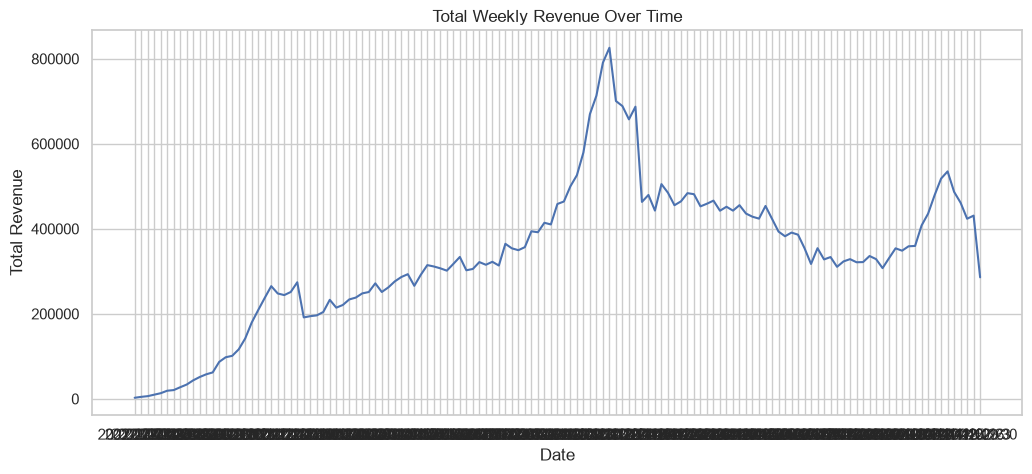

In [31]:
plt.figure(figsize=(12, 5))

# Group by date index to plot total weekly revenue
weekly_revenue = sorted_df1.groupby('date')['revenue'].sum()

sns.lineplot(x=weekly_revenue.index, y=weekly_revenue.values)
plt.title('Total Weekly Revenue Over Time')
plt.xlabel('Date')
plt.ylabel('Total Revenue')
plt.grid(True)
plt.show()

In [32]:
sns.set_theme(style="whitegrid")
# 1. Category-level performance
cat_summary =sorted_df1.groupby('category').agg(
    total_revenue=('revenue', 'sum'),
    total_units_sold=('units_sold', 'sum'),
    avg_price=('price', 'mean'),
    avg_return_rate=('returns', lambda x: x.sum() / sorted_df1.loc[x.index, 'units_sold'].sum())
).reset_index().sort_values(by='total_revenue', ascending=False)

print("--- Category Performance ---")
print(cat_summary)

--- Category Performance ---
         category  total_revenue  total_units_sold   avg_price  \
3     electronics    15948855.00            101557  174.891641   
5    home_kitchen     6284055.00            120129   58.303342   
0         apparel     5479256.25            175932   43.719482   
6  sports_outdoor     5468172.50             91954   68.028830   
4         grocery     3505957.50            246216   14.573073   
1          beauty     3144912.50            141554   24.295652   
7      toys_games     2986961.25             95786   34.005619   
2     books_media     1307615.00             71097   19.431964   

   avg_return_rate  
3         0.088847  
5         0.098144  
0         0.280756  
6         0.119582  
4         0.020145  
1         0.079143  
7         0.070710  
2         0.049383  


In [33]:
# 2. Regional analysis
region_summary = sorted_df1.groupby('region').agg(
    total_revenue=('revenue', 'sum'),
    total_units=('units_sold', 'sum'),
    stockout_rate=('stockout', 'mean'),
    promo_rate=('on_promo', 'mean')
).reset_index()

print("\n--- Regional Summary ---")
print(region_summary)


--- Regional Summary ---
    region  total_revenue  total_units  stockout_rate  promo_rate
0  Central     7238522.50       178892       0.043321    0.114079
1     East     7276746.25       175824       0.042857    0.114059
2    North    11474183.75       292769       0.044167    0.112947
3    South     9767476.25       191845       0.043159    0.112298
4     West     8368856.25       204895       0.043452    0.113690


In [34]:
# 3. Lost Revenue Due to Stockouts
sorted_df1['lost_sales'] = np.where(sorted_df1['stockout'] == 1, sorted_df1['true_demand'] - sorted_df1['units_sold'], 0)
sorted_df1['lost_revenue'] = sorted_df1['lost_sales'] * sorted_df1['price']

lost_rev_by_cat = sorted_df1.groupby('category').agg(
    total_lost_revenue=('lost_revenue', 'sum'),
    stockout_incidents=('stockout', 'sum')
).reset_index().sort_values(by='total_lost_revenue', ascending=False)

print("\n--- Lost Revenue by Category ---")
print(lost_rev_by_cat)


--- Lost Revenue by Category ---
         category  total_lost_revenue  stockout_incidents
3     electronics           687465.00                 125
0         apparel           294603.75                 133
5    home_kitchen           260955.00                 134
6  sports_outdoor           235375.00                 126
4         grocery           141011.25                 137
7      toys_games           128800.00                 141
1          beauty           126887.50                 124
2     books_media            52455.00                 136


/var/folders/34/6j1k3sv51xg708qq_m56pkr80000gn/T/ipykernel_65422/2545370249.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_summary, x='total_revenue', y='category', palette='Blues_r')
/var/folders/34/6j1k3sv51xg708qq_m56pkr80000gn/T/ipykernel_65422/2545370249.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lost_rev_by_cat, x='total_lost_revenue', y='category', palette='Reds_r')


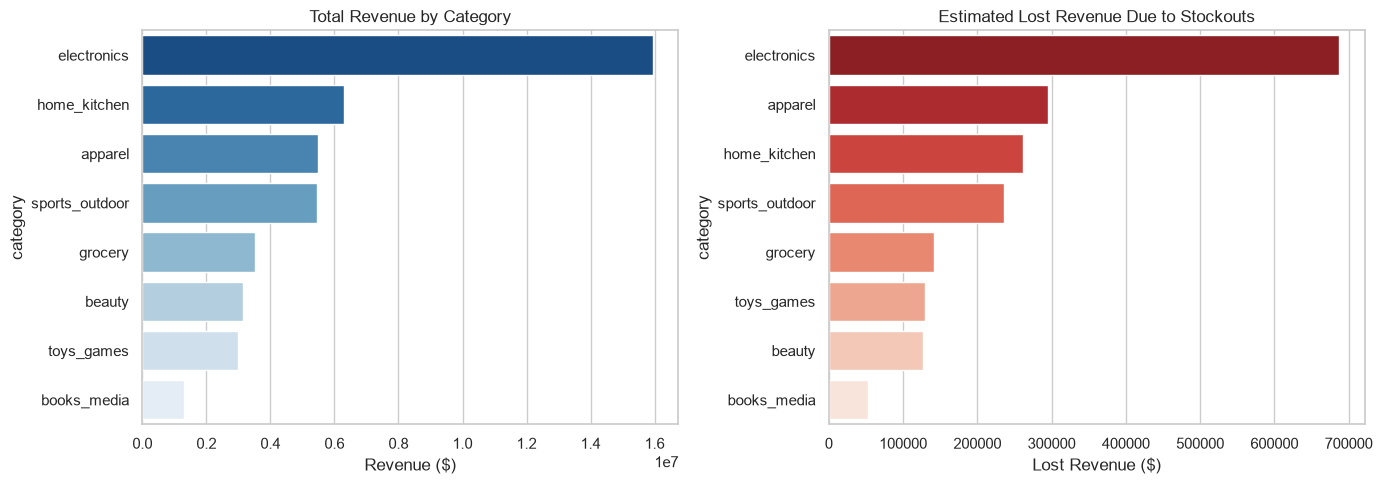

In [35]:
# 4. Save visualization for Category Revenue & Lost Revenue
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.barplot(data=cat_summary, x='total_revenue', y='category', palette='Blues_r')
plt.title('Total Revenue by Category')
plt.xlabel('Revenue ($)')

plt.subplot(1, 2, 2)
sns.barplot(data=lost_rev_by_cat, x='total_lost_revenue', y='category', palette='Reds_r')
plt.title('Estimated Lost Revenue Due to Stockouts')
plt.xlabel('Lost Revenue ($)')

plt.tight_layout()
plt.show()
plt.close()

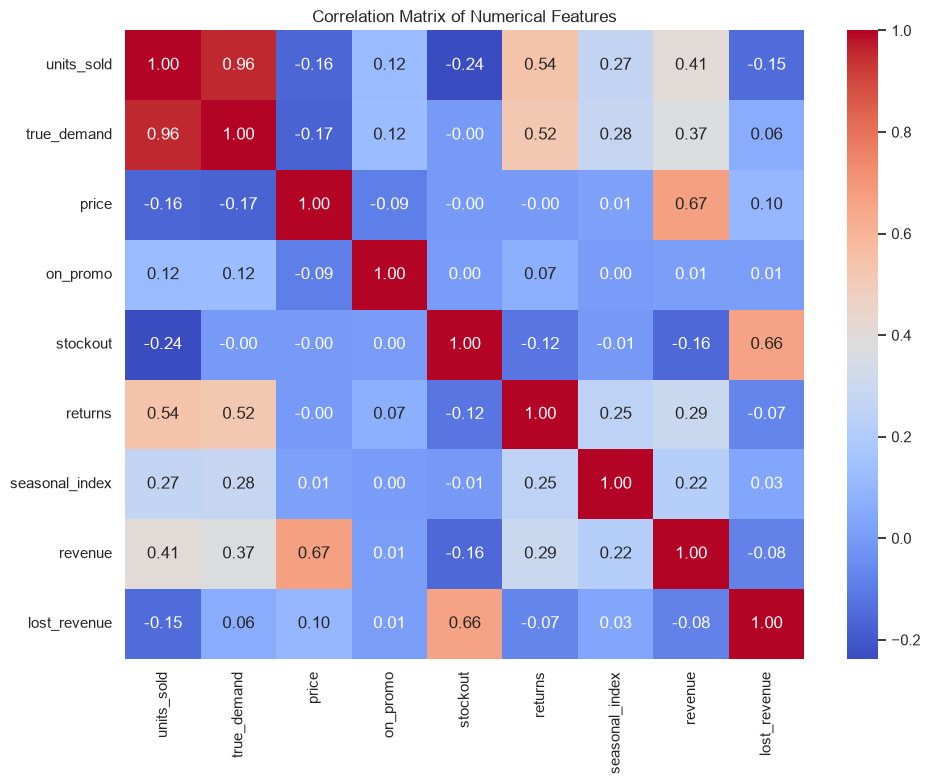


Plots generated successfully.


In [36]:
# 5. Correlation Heatmap
plt.figure(figsize=(10, 8))
numeric_cols = ['units_sold', 'true_demand', 'price', 'on_promo', 'stockout', 'returns', 'seasonal_index', 'revenue', 'lost_revenue']
sns.heatmap(sorted_df1[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()
plt.close()

print("\nPlots generated successfully.")
